Loading data

In [1]:
from pathlib import Path
import pandas as pd
from IPython import display

ROOT = Path.cwd().parent
raw_path = ROOT / "data" / "raw" / "raw_data.csv"
df = pd.read_csv(raw_path)

Structure & Inspection

In [2]:
df.info()
df.shape
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


Identify Numerical and Categorical Columns:

In [3]:
Numerical_columns = df.select_dtypes(include="number").columns
Categorical_columns = df.select_dtypes(include=["str", "object"]).columns

print(Numerical_columns)
print(Categorical_columns)

Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate'],
      dtype='str')
Index(['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job',
       'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk'],
      dtype='str')


Hygiene check (missing, duplicate, aberration):

In [4]:
records = []

for col in Numerical_columns:

    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]

    records.append({
        'column': col,
        'missing_values': df[col].isnull().sum(),
        'outliers': len(outliers)
    })

for col in Categorical_columns:
    records.append({
        'column': col,
        'missing_values': df[col].isnull().sum(),
        'outliers': 0
    })

df_check_analytics = pd.DataFrame(records).set_index("column")
print("total duplicates: ", df.drop(columns="Student_ID").duplicated().sum())
df_check_analytics

total duplicates:  0


,missing_values,outliers
column,,
Age,0,4
Year_of_Study,0,0
Sleep_Hours,62,2
Study_Hours_Per_Week,0,7
GPA,38,9
Social_Media_Hours,58,20
Screen_Time_Hours,0,7
Financial_Stress,91,0
Family_Support,54,0


Correlation Matrix (Numerical Features + Target)

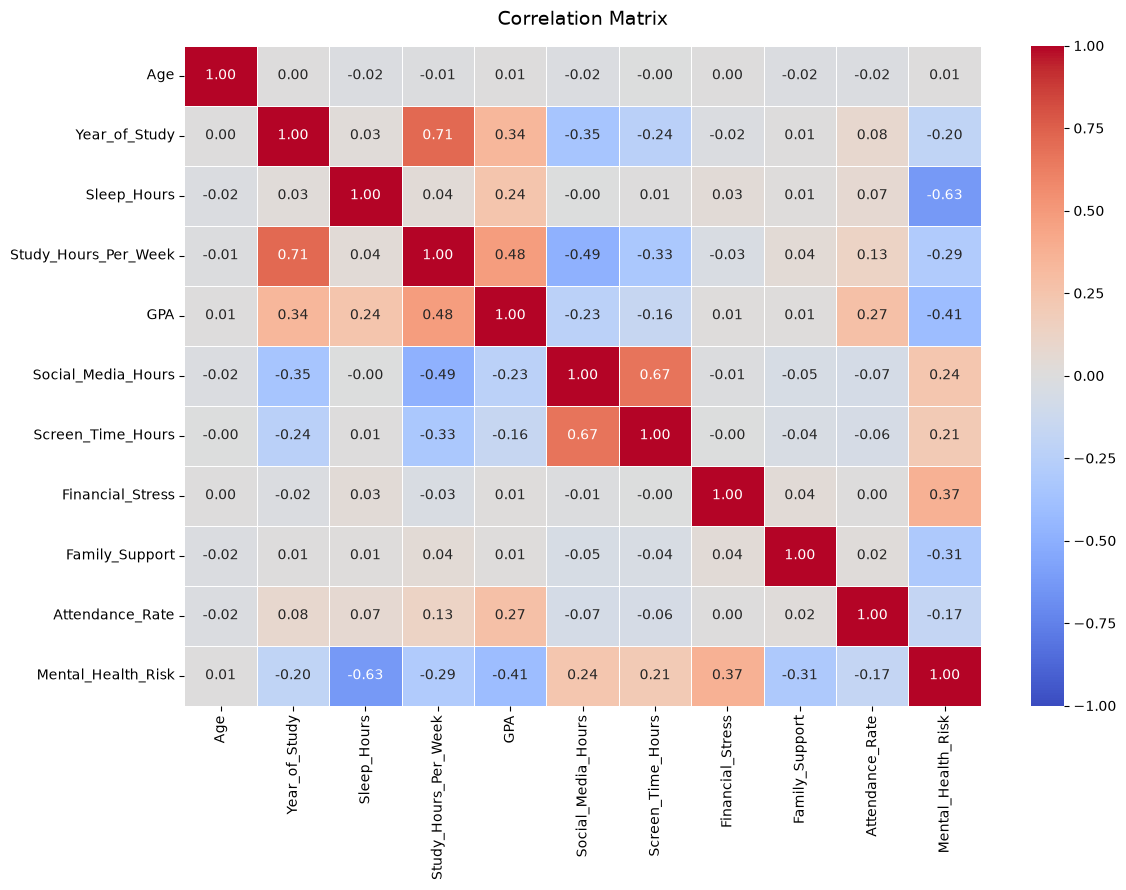

In [6]:
df_corr = df[Numerical_columns].copy()
risk_mapping = {'Low': 0, 'Moderate': 1, 'High': 2}
df_corr['Mental_Health_Risk'] = df['Mental_Health_Risk'].map(risk_mapping)

corr_matrix = df_corr.corr(method='spearman')

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Correlation Matrix", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

Analytics for Categorical Columns:

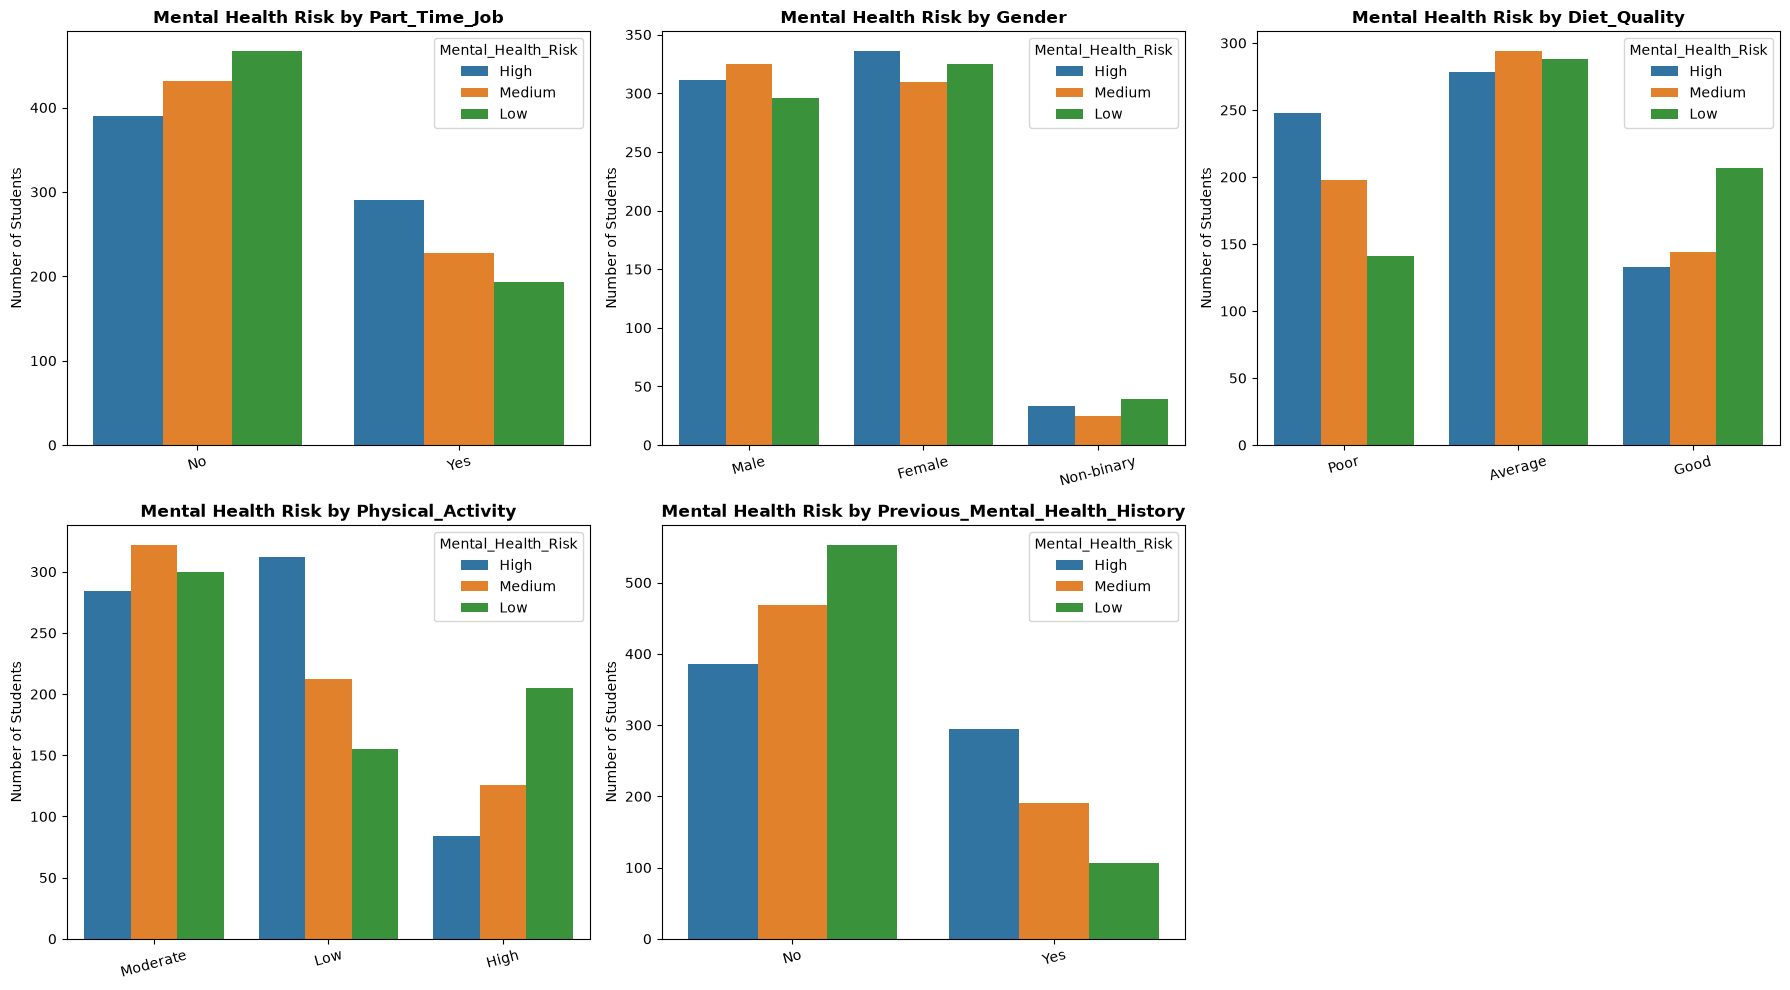

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(set(Categorical_columns)-{"Student_ID", "Mental_Health_Risk"}):
    sns.countplot(
        data=df,
        x=col,
        hue='Mental_Health_Risk',
        ax=axes[i]
    )
    axes[i].set_title(f"Mental Health Risk by {col}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Number of Students")
    axes[i].tick_params(axis='x', rotation=15)

axes[5].remove()
plt.tight_layout()
plt.show()

IQR Boxplot Grid

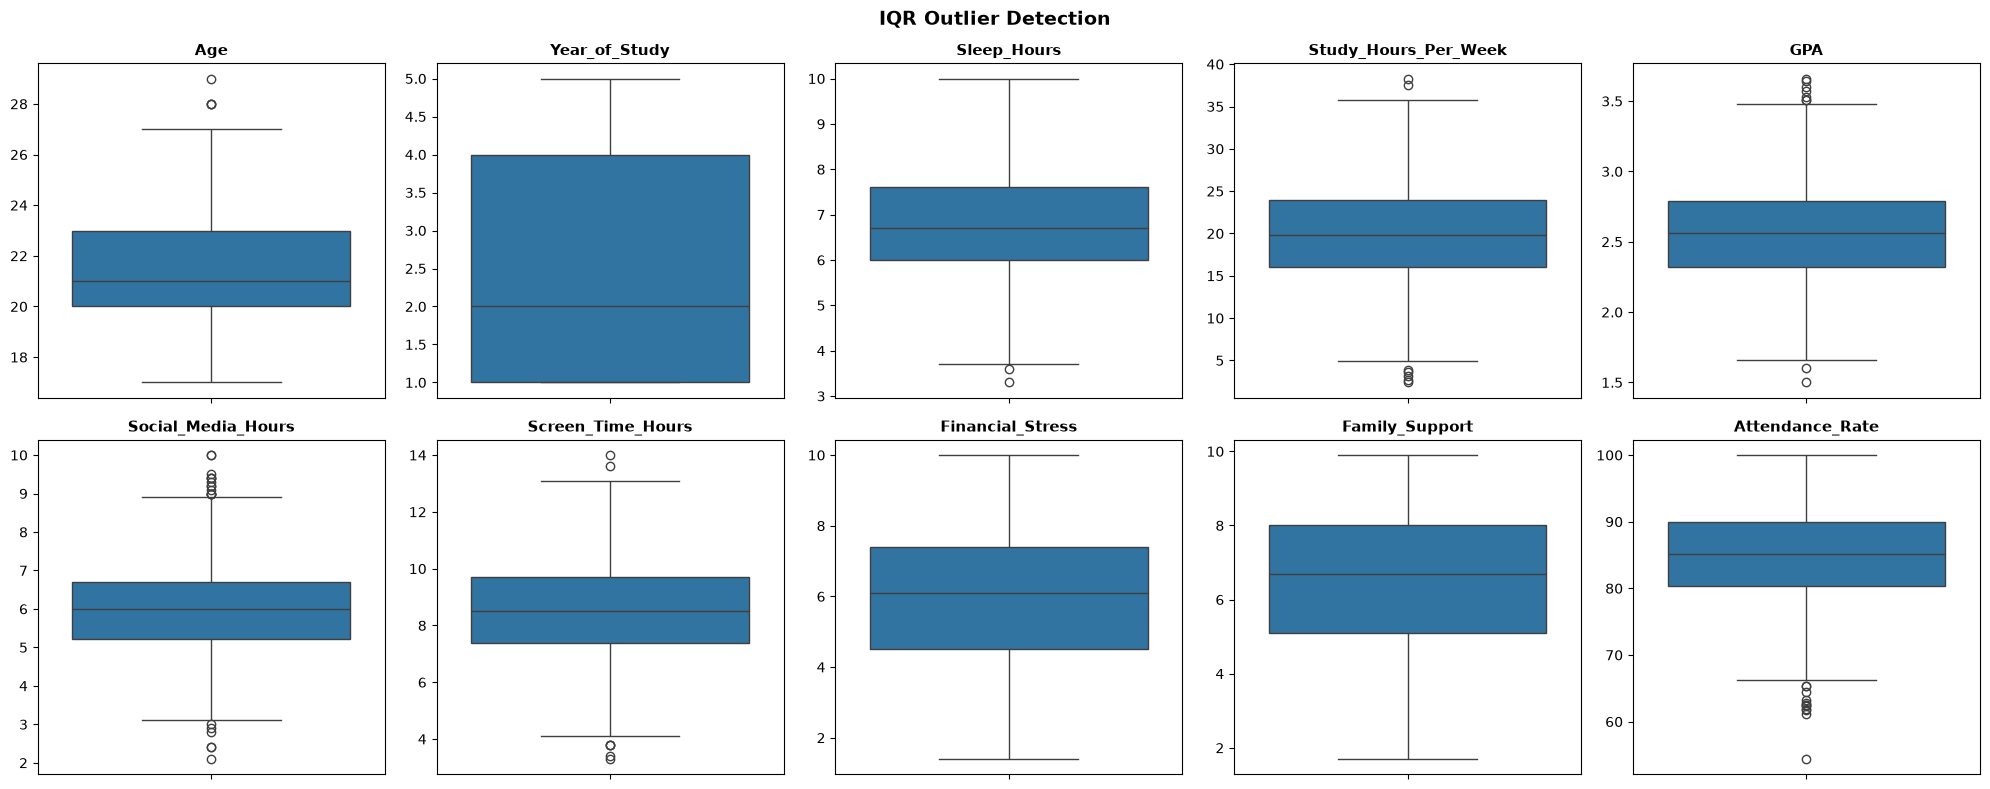

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, col in enumerate(Numerical_columns):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_ylabel("")

plt.suptitle("IQR Outlier Detection", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()